# SH-ITA final analysis with Penman-Monteith SPEI (1985-2020)

**Design (as decided)**
- **PET:** FAO-56 Penman-Monteith (from `extra_variables.xlsx`) is the primary PET for SPEI. Because solar radiation starts in 1984, indices are fitted on 1984-2022 and analysed on **1985-2002 (first half) vs 2003-2020 (second half)**, 216 months each.
- **SPI:** gamma + zero mass, fitted per calendar month on the same 1984-2022 record. **SPEI:** rank-based (normal quantile) per calendar month, because the 3-parameter log-logistic is invalid in many site-months.
- **Labels:** class shift D with two-sided bootstrap p-values, **Holm-adjusted across the three classes** and judged at **simulation-calibrated significance levels** (0.010 for 3-month and 0.007 for 12-month series; IISC 0.020 and 0.003; A 0.025 and 0.005; ICSC 0.05); a label is *stable* only if identical at all block lengths. A star in the figure legends marks a result significant at its calibrated level (3-month: 6/12/24; 12-month: 12/24/48 months).
- **Also reported:** IISC, ICSC and A = D_high - D_low with 95% intervals; modified Mann-Kendall; Sen (2017) and Alashan (2020) analytic ITA tests.

Needs `reshaped_climate_data.xlsx` and `extra_variables.xlsx` in the same folder. Run time about 2-3 minutes.

In [1]:
import os, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display
from math import sin, radians, acos, tan, pi
from scipy import stats

# ---- EDIT THESE TWO LINES IF NEEDED -------------------------------------------
DATA = 'reshaped_climate_data.xlsx'   # the workbook your first notebook created (same folder as this notebook)
OUT  = 'sh_ita_outputs'               # folder where tables and figures will be saved
# ------------------------------------------------------------------------------
os.makedirs(OUT, exist_ok=True)
%matplotlib inline

## Settings

In [2]:
LAT = {'YENAGOA': 4.95, 'IKOT AKPADEN': 4.62, 'IBADAN': 7.38, 'ABUJA': 9.07,
       'JALINGO': 8.89, 'SOKOTO': 13.01, 'GOMBE': 10.28, 'KUKAWA': 12.92}
X_START, X_END = '1982-01-01', '2001-12-31'      # first half  (240 months)
Y_START, Y_END = '2002-01-01', '2021-12-31'      # second half (240 months)
B = 2000                                          # bootstrap replicates
BLOCK = {3: 12, 12: 24}                           # block length (months) by timescale
MIN_N = 10                                        # min class size for a trend label
SEED = 2026
CLIP = 1e-6
COL = {'Low': 'red', 'Medium': 'orange', 'High': 'blue'}   # ONE colour convention for every figure

## Load data

In [3]:
P = pd.read_excel(DATA, 'Precip_Wide', index_col='Date').drop(columns=['Year', 'Month'], errors='ignore')
T = pd.read_excel(DATA, 'Temp_Wide', index_col='Date').drop(columns=['Year', 'Month'], errors='ignore')
P.index = pd.to_datetime(P.index); T.index = pd.to_datetime(T.index)

## PET (Thornthwaite)

In [4]:
MID = [15, 46, 75, 105, 135, 166, 196, 227, 258, 288, 319, 349]
def daylength(lat, month):
    decl = radians(23.45 * sin(radians(360 * (284 + MID[month - 1]) / 365.0)))
    x = max(min(-tan(radians(lat)) * tan(decl), 0.999999), -0.999999)
    return 24.0 / pi * acos(x)
def thornthwaite(t, lat):
    clim = t.groupby(t.index.month).mean()
    I = ((clim.clip(lower=0) / 5.0) ** 1.514).sum()
    a = 6.75e-7 * I ** 3 - 7.71e-5 * I ** 2 + 1.792e-2 * I + 0.49239
    out = [16.0 * (10.0 * v / I) ** a * (daylength(lat, d.month) / 12.0) * (d.days_in_month / 30.0)
           if v > 0 else 0.0 for d, v in t.items()]
    return pd.Series(out, index=t.index)
PET = pd.DataFrame({l: thornthwaite(T[l], LAT[l]) for l in P.columns})

## SPI and SPEI per calendar month

In [5]:
def roll(s, sc): return s.rolling(sc, min_periods=sc).sum()
def spi_cm(p, sc):
    a = roll(p, sc); out = pd.Series(np.nan, index=a.index)
    for m in range(1, 13):
        v = a[a.index.month == m].dropna(); nz = v[v > 0]
        if len(nz) < 10: continue
        q = (v == 0).mean()
        g, _, sc_ = stats.gamma.fit(nz.values, floc=0)
        cdf = np.where(v.values <= 0, q, q + (1 - q) * stats.gamma.cdf(v.values, g, loc=0, scale=sc_))
        out[v.index] = stats.norm.ppf(np.clip(cdf, CLIP, 1 - CLIP))
    return out
def spei_cm(p, pet, sc):
    a = roll(p - pet, sc); out = pd.Series(np.nan, index=a.index)
    for m in range(1, 13):
        v = a[a.index.month == m].dropna(); N = len(v)
        if N < 20: continue
        out[v.index] = stats.norm.ppf((stats.rankdata(v.values) - 0.44) / (N + 0.12))
    return out

## SH-ITA statistics and bootstrap

In [6]:
def slope(x, y):
    return np.nan if len(x) < 2 or np.ptp(x) == 0 else np.polyfit(x, y, 1)[0]
def ita_stats(x, y):
    xs, ys = np.sort(x), np.sort(y)
    cls = np.where(xs <= -1, 0, np.where(xs >= 1, 2, 1))          # class from FIRST-half value
    r = {}
    for k, nm in enumerate(['low', 'med', 'high']):
        m = cls == k
        r['n_' + nm] = int(m.sum()); r['slope_' + nm] = slope(xs[m], ys[m])
        r['D_' + nm] = (ys[m] - xs[m]).mean() if m.any() else np.nan
    r['IISC'] = (ys.mean() - xs.mean()) / np.abs(xs).mean()
    sl, sh = r['slope_low'], r['slope_high']
    r['ICSC'] = (sh - sl) / abs(sh + sl) if np.isfinite(sl) and np.isfinite(sh) and abs(sh + sl) > 0 else np.nan
    r['A'] = r['D_high'] - r['D_low']
    return r, xs, ys, cls
def cbb(a, L, rng):
    n = len(a); nb = int(np.ceil(n / L))
    return a[(rng.integers(0, n, nb)[:, None] + np.arange(L)).ravel()[:n] % n]
KEYS = ['D_low', 'D_med', 'D_high', 'IISC', 'ICSC', 'A']
def analyse(s, L, seed):
    x = s.loc[X_START:X_END].dropna().values; y = s.loc[Y_START:Y_END].dropna().values
    assert len(x) == len(y), 'halves differ in length: %d vs %d' % (len(x), len(y))
    base, xs, ys, cls = ita_stats(x, y); rng = np.random.default_rng(seed)
    bt = {k: [] for k in KEYS}
    for _ in range(B):
        r, *_ = ita_stats(cbb(x, L, rng), cbb(y, L, rng))
        for k in KEYS: bt[k].append(r[k])
    res = dict(base); res['n'] = len(x)
    for k in KEYS:
        v = np.array(bt[k], float); v = v[np.isfinite(v)]
        res[k + '_lo'], res[k + '_hi'] = (np.percentile(v, 2.5), np.percentile(v, 97.5)) if len(v) > 100 else (np.nan, np.nan)
    for nm in ['low', 'med', 'high']:
        lo, hi = res['D_%s_lo' % nm], res['D_%s_hi' % nm]
        res['label_' + nm] = '-' if (res['n_' + nm] < MIN_N or not np.isfinite(lo)) else ('Yes(+)' if lo > 0 else 'Yes(-)' if hi < 0 else 'No')
    return res, xs, ys, cls

## Penman-Monteith PET (and the other formulations for reference)

In [7]:
def Ra_daily(lat_deg, doy):
    """Extraterrestrial radiation, MJ m-2 day-1 (FAO-56)."""
    phi = np.radians(lat_deg); dr = 1 + 0.033 * np.cos(2 * np.pi * doy / 365.0)
    dec = 0.409 * np.sin(2 * np.pi * doy / 365.0 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(dec), -1, 1))
    return (24 * 60 / np.pi) * 0.0820 * dr * (ws * np.sin(phi) * np.sin(dec) + np.cos(phi) * np.cos(dec) * np.sin(ws))
def es_kpa(t): return 0.6108 * np.exp(17.27 * t / (t + 237.3))
def monthly_from_daily(daily, idx): return pd.Series(np.asarray(daily) * idx.days_in_month.values, index=idx)
def doy_mid(idx): return np.array([pd.Timestamp(d.year, d.month, 15).dayofyear for d in idx])

def pet_hamon(t, lat, kpec=1.0):
    """Hamon (1961): PET[mm/day] = 0.1651 * (N/12) * 216.7 * esat[mb]/(T+273.3) * kpec."""
    N = np.array([daylength(lat, d.month) for d in t.index])
    rhosat = 216.7 * 6.108 * np.exp(17.27 * t.values / (t.values + 237.3)) / (t.values + 273.3)
    return monthly_from_daily(np.where(t.values > 0, 0.1651 * (N / 12.0) * rhosat * kpec, 0.0), t.index)
def pet_oudin(t, lat):
    """Oudin et al. (2005): PET[mm/day] = 0.408 * Ra * (T + 5) / 100 if T + 5 > 0."""
    ra = Ra_daily(lat, doy_mid(t.index))
    return monthly_from_daily(np.where(t.values + 5 > 0, 0.408 * ra * (t.values + 5) / 100.0, 0.0), t.index)
def pet_hargreaves(tmax, tmin, lat):
    """Hargreaves-Samani: PET[mm/day] = 0.0023 * 0.408*Ra * (Tmean + 17.8) * sqrt(Tmax - Tmin), Tmean = (Tmax+Tmin)/2."""
    tm = (tmax + tmin) / 2; ra = Ra_daily(lat, doy_mid(tm.index))
    return monthly_from_daily(0.0023 * 0.408 * ra * (tm.values + 17.8) * np.sqrt(np.clip(tmax.values - tmin.values, 0, None)), tm.index)
def pet_pm_fao56(tmax, tmin, rh, u2, rs, lat, elev):
    """FAO-56 Penman-Monteith on monthly mean data (G = 0). rs in MJ m-2 day-1, u2 m/s at 2 m, rh %."""
    Tx, Tn = tmax.values, tmin.values; T = (Tx + Tn) / 2
    Pk = 101.3 * ((293 - 0.0065 * elev) / 293) ** 5.26; gamma = 0.000665 * Pk
    delta = 4098 * es_kpa(T) / (T + 237.3) ** 2
    es = (es_kpa(Tx) + es_kpa(Tn)) / 2; ea = np.clip(rh.values, 1, 100) / 100.0 * es
    ra = Ra_daily(lat, doy_mid(tmax.index)); rso = (0.75 + 2e-5 * elev) * ra
    rn = 0.77 * rs.values - 4.903e-9 * (((Tx + 273.16) ** 4 + (Tn + 273.16) ** 4) / 2) * (0.34 - 0.14 * np.sqrt(ea)) * (1.35 * np.clip(rs.values / rso, 0.3, 1.0) - 0.35)
    et0 = (0.408 * delta * rn + gamma * 900 / (T + 273) * u2.values * (es - ea)) / (delta + gamma * (1 + 0.34 * u2.values))
    return monthly_from_daily(np.clip(et0, 0, None), tmax.index)

PETS = {'Thornthwaite': PET.copy(),
        'Hamon': pd.DataFrame({l: pet_hamon(T[l], LAT[l]) for l in P.columns}),
        'Oudin': pd.DataFrame({l: pet_oudin(T[l], LAT[l]) for l in P.columns})}
XV = 'extra_variables.xlsx'
if os.path.exists(XV):
    ex = {s: pd.read_excel(XV, s, index_col='Date') for s in ('Tmax', 'Tmin', 'RH', 'Wind', 'Srad')}
    ELEV = pd.read_excel(XV, 'Elevation').set_index('Location')['Elevation_m'].to_dict()
    PETS['Hargreaves'] = pd.DataFrame({l: pet_hargreaves(ex['Tmax'][l], ex['Tmin'][l], LAT[l]) for l in P.columns})
    PETS['Penman-Monteith'] = pd.DataFrame({l: pet_pm_fao56(ex['Tmax'][l], ex['Tmin'][l], ex['RH'][l], ex['Wind'][l], ex['Srad'][l], LAT[l], ELEV[l]) for l in P.columns})
else:
    print('extra_variables.xlsx not found: Hargreaves and Penman-Monteith skipped.')
print('PET formulations:', list(PETS))

PET formulations: ['Thornthwaite', 'Hamon', 'Oudin', 'Hargreaves', 'Penman-Monteith']


In [8]:
# ---- analysis window for the whole paper (Penman-Monteith needs radiation, available from 1984)
FIT_START = '1984-01-01'
X_START, X_END = '1985-01-01', '2002-12-31'
Y_START, Y_END = '2003-01-01', '2020-12-31'
PM = PETS['Penman-Monteith']
print('First half:', X_START[:7], 'to', X_END[:7], '| second half:', Y_START[:7], 'to', Y_END[:7])

First half: 1985-01 to 2002-12 | second half: 2003-01 to 2020-12


## Comparators: Mann-Kendall (Hamed-Rao), Sen (2017), Alashan (2020)

In [9]:
def sen_slope(x):
    x = np.asarray(x, float); n = len(x)
    return np.median(np.concatenate([(x[k:] - x[:-k]) / k for k in range(1, n)]))

def mk_test(x, hr=True):
    """Mann-Kendall S, Z, p-value (two-sided) and Sen slope per time step. hr=True applies Hamed & Rao (1998)."""
    x = np.asarray(x, float); n = len(x)
    S = sum(np.sign(x[i + 1:] - x[i]).sum() for i in range(n - 1))
    _, cnt = np.unique(x, return_counts=True)
    var = (n * (n - 1) * (2 * n + 5) - np.sum(cnt * (cnt - 1) * (2 * cnt + 5))) / 18.0
    beta = sen_slope(x); f = 1.0
    if hr:
        r = stats.rankdata(x - beta * np.arange(n)); r = r - r.mean(); den = (r * r).sum()
        lim = stats.norm.ppf(0.975) / np.sqrt(n); sni = 0.0
        for k in range(1, n - 1):
            a = (r[:-k] * r[k:]).sum() / den
            if abs(a) > lim: sni += (n - k) * (n - k - 1) * (n - k - 2) * a
        f = 1 + 2.0 / (n * (n - 1) * (n - 2)) * sni
        f = f if f > 0 else 1.0
    z = 0.0 if S == 0 else (S - np.sign(S)) / np.sqrt(var * f)
    return dict(S=S, Z=z, p=2 * (1 - stats.norm.cdf(abs(z))), sen=beta, vcf=f)

def direction(p, est, alpha=0.05):
    return '0' if not (p < alpha) else ('+' if est > 0 else '-')

In [10]:
def sen2017_sig(x1, x2, alpha=0.05):
    n = len(x1) + len(x2); s = 2 * (x2.mean() - x1.mean()) / n
    rho = np.corrcoef(np.sort(x1), np.sort(x2))[0, 1]
    sd = np.sqrt(8.0 * np.var(np.concatenate([x1, x2]), ddof=1) * max(1 - rho, 1e-12)) / n
    return abs(s / sd) > stats.norm.ppf(1 - alpha / 2)
def alashan2020_sig(x1, x2, alpha=0.05):
    a, b = np.sort(x1), np.sort(x2); n = len(a) + len(b); s = 2 * (b.mean() - a.mean()) / n
    s1, s2 = a.std(ddof=1), b.std(ddof=1); rho = np.corrcoef(a, b)[0, 1]
    sd = (2.0 / n) * np.sqrt(max(s1 ** 2 + s2 ** 2 - 2 * rho * s1 * s2, 1e-12))
    return abs(s / sd) > stats.norm.ppf(1 - alpha / 2)

## Final analysis function (bootstrap p-values + Holm correction)

In [11]:
BL = {3: (6, 12, 24), 12: (12, 24, 48)}       # block lengths tried; the middle one is primary
ALPHA = 0.05
# Effective significance levels that give a 5% false-positive rate under no change (SH-ITA_synthetic_experiments_v2.ipynb, full-size run),
# calibrated at persistence matching the real series (lag-1 autocorrelation 0.59-0.86 at 3 months, 0.94-0.98 at 12 months).
ALPHA_CAL = {3: dict(cls=0.010, IISC=0.020, A=0.025, ICSC=0.05), 12: dict(cls=0.007, IISC=0.003, A=0.005, ICSC=0.05)}

def boot_p(v):
    """Two-sided percentile-bootstrap p-value for H0: statistic = 0."""
    v = v[np.isfinite(v)]
    return np.nan if len(v) < 100 else max(2 * min((v <= 0).mean(), (v >= 0).mean()), 1.0 / (len(v) + 1))

def holm(pvals):
    """Holm step-down adjustment; NaN entries (untestable classes) are ignored."""
    p = np.array(pvals, float); out = np.full_like(p, np.nan); ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]; m = len(order); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (m - rank) * p[i])); out[i] = run
    return out

def lab(D, p, n, alpha=None):
    alpha = ALPHA if alpha is None else alpha
    return '-' if (n < MIN_N or not np.isfinite(p)) else ('No' if p >= alpha else ('Yes(+)' if D > 0 else 'Yes(-)'))

def analyse_final(s, L, seed, B=B, sc=None):
    a = ALPHA_CAL[sc] if sc in ALPHA_CAL else dict(cls=ALPHA, IISC=ALPHA, A=ALPHA, ICSC=ALPHA)
    x = s.loc[X_START:X_END].dropna().values; y = s.loc[Y_START:Y_END].dropna().values
    assert len(x) == len(y)
    base, xs, ys, cls = ita_stats(x, y); rng = np.random.default_rng(seed)
    bt = {k: [] for k in KEYS}
    for _ in range(B):
        r, *_ = ita_stats(cbb(x, L, rng), cbb(y, L, rng))
        for k in KEYS: bt[k].append(r[k])
    bt = {k: np.array(v, float) for k, v in bt.items()}
    res = dict(base, n=len(x), L=L)
    for k in KEYS:
        v = bt[k][np.isfinite(bt[k])]
        res[k + '_lo'], res[k + '_hi'] = (np.percentile(v, 2.5), np.percentile(v, 97.5)) if len(v) > 100 else (np.nan, np.nan)
    names = ['low', 'med', 'high']
    p_raw = [boot_p(bt['D_' + nm]) if base['n_' + nm] >= MIN_N else np.nan for nm in names]
    p_adj = holm(p_raw)
    for i, nm in enumerate(names):
        res['p_raw_' + nm] = p_raw[i]; res['p_holm_' + nm] = p_adj[i]
        res['label_raw_' + nm] = lab(base['D_' + nm], p_raw[i], base['n_' + nm])
        res['label_holm05_' + nm] = lab(base['D_' + nm], p_adj[i], base['n_' + nm])               # Holm, nominal 0.05
        res['label_holm_' + nm] = lab(base['D_' + nm], p_adj[i], base['n_' + nm], a['cls'])     # Holm, calibrated level
    for k in ('IISC', 'ICSC', 'A'):
        res['p_' + k] = boot_p(bt[k])
        res[k + '_clear'] = bool(np.isfinite(res['p_' + k]) and res['p_' + k] < a[k])            # calibrated level
        res[k + '_clear05'] = bool(np.isfinite(res['p_' + k]) and res['p_' + k] < ALPHA)          # nominal 0.05
    return res

## Run on all 32 series (all block lengths)

In [12]:
order = ['YENAGOA', 'IKOT AKPADEN', 'IBADAN', 'ABUJA', 'JALINGO', 'SOKOTO', 'GOMBE', 'KUKAWA']
rows, SER = [], {}
P84 = P.loc[FIT_START:]
for sc in (3, 12):
    for loc in order:
        for kind in ('SPEI', 'SPI'):
            s_full = spei_cm(P84[loc], PM[loc].loc[FIT_START:], sc) if kind == 'SPEI' else spi_cm(P84[loc], sc)
            SER[(loc, kind, sc)] = s_full
            s = s_full.loc[X_START:Y_END].dropna()
            x1, x2 = s.loc[X_START:X_END].values, s.loc[Y_START:Y_END].values
            m = mk_test(s.values, hr=True)
            for L in BL[sc]:
                r = analyse_final(s, L, SEED, sc=sc)
                r.update(location=loc.title(), index=f'{kind}-{sc}', scale=sc, primary=(L == BL[sc][1]),
                         MMK_sig=m['p'] < 0.05, Sen2017_sig=sen2017_sig(x1, x2), Alashan2020_sig=alashan2020_sig(x1, x2))
                rows.append(r)
            print('done', kind, sc, loc, flush=True)
ALL = pd.DataFrame(rows)
PRIM = ALL[ALL.primary].reset_index(drop=True)

done SPEI 3 YENAGOA
done SPI 3 YENAGOA
done SPEI 3 IKOT AKPADEN
done SPI 3 IKOT AKPADEN
done SPEI 3 IBADAN
done SPI 3 IBADAN
done SPEI 3 ABUJA
done SPI 3 ABUJA
done SPEI 3 JALINGO
done SPI 3 JALINGO
done SPEI 3 SOKOTO
done SPI 3 SOKOTO
done SPEI 3 GOMBE
done SPI 3 GOMBE
done SPEI 3 KUKAWA
done SPI 3 KUKAWA
done SPEI 12 YENAGOA
done SPI 12 YENAGOA
done SPEI 12 IKOT AKPADEN
done SPI 12 IKOT AKPADEN
done SPEI 12 IBADAN
done SPI 12 IBADAN
done SPEI 12 ABUJA
done SPI 12 ABUJA
done SPEI 12 JALINGO
done SPI 12 JALINGO
done SPEI 12 SOKOTO
done SPI 12 SOKOTO
done SPEI 12 GOMBE
done SPI 12 GOMBE
done SPEI 12 KUKAWA
done SPI 12 KUKAWA


## Block-length stability of the Holm-adjusted labels

In [13]:
def stable(g, nm):
    v = g['label_holm_' + nm].unique(); return len(v) == 1
stab = ALL.groupby(['location', 'index']).apply(lambda g: pd.Series({f'stable_{nm}': stable(g, nm) for nm in ('low', 'med', 'high')})).reset_index()
PRIM = PRIM.merge(stab, on=['location', 'index'])
for nm in ('low', 'med', 'high'):
    PRIM['final_' + nm] = np.where(PRIM['stable_' + nm], PRIM['label_holm_' + nm], PRIM['label_holm_' + nm] + ' (unstable)')
PRIM[['location', 'index', 'n_low', 'n_med', 'n_high', 'final_low', 'final_med', 'final_high']]

,location,index,n_low,n_med,n_high,final_low,final_med,final_high
0,Yenagoa,SPEI-3,29,144,43,No,No,No
1,Yenagoa,SPI-3,27,140,49,No,No,No
2,Ikot Akpaden,SPEI-3,40,143,33,No,No,No
3,Ikot Akpaden,SPI-3,35,146,35,No,No,No
4,Ibadan,SPEI-3,42,153,21,No,No,No
5,Ibadan,SPI-3,50,142,24,No,No,No
6,Abuja,SPEI-3,20,142,54,No,Yes(-),Yes(-)
7,Abuja,SPI-3,26,144,46,No,Yes(-),No
8,Jalingo,SPEI-3,17,149,50,No,Yes(-),No
9,Jalingo,SPI-3,21,152,43,No,No (unstable),Yes(-)


## Summary and export

In [14]:
def ci(r, k, d=2):
    return '%.*f [%.*f, %.*f]' % (d, r[k], d, r[k + '_lo'], d, r[k + '_hi']) if np.isfinite(r[k]) else 'n/a'
yes = lambda c: c.astype(str).str.startswith('Yes')
print('Class labels "Yes" over the testable class tests (3 classes x 32 series):')
print('  unadjusted bootstrap p<0.05                 :', int(sum(yes(PRIM['label_raw_' + n]).sum() for n in ('low', 'med', 'high'))))
print('  Holm-adjusted, nominal level 0.05           :', int(sum(yes(PRIM['label_holm05_' + n]).sum() for n in ('low', 'med', 'high'))))
print('  Holm-adjusted, calibrated level             :', int(sum(yes(PRIM['label_holm_' + n]).sum() for n in ('low', 'med', 'high'))))
print('  calibrated AND stable across block lengths  :', int(sum((yes(PRIM['label_holm_' + n]) & PRIM['stable_' + n]).sum() for n in ('low', 'med', 'high'))))
for n in ('low', 'med', 'high'):
    print(f'     {n:5s} class (calibrated): Yes =', int(yes(PRIM['label_holm_' + n]).sum()), '| untestable (n<10) =', int((PRIM['label_holm_' + n] == '-').sum()))
print('Overall (32 series), calibrated level:  IISC', int(PRIM.IISC_clear.sum()), '| A', int(PRIM.A_clear.sum()), '| ICSC', int(PRIM.ICSC_clear.sum()),
      '||  nominal 0.05:  IISC', int(PRIM.IISC_clear05.sum()), '| A', int(PRIM.A_clear05.sum()), '| ICSC', int(PRIM.ICSC_clear05.sum()))
print('Comparators: modified MK', int(PRIM.MMK_sig.sum()), '| Sen2017', int(PRIM.Sen2017_sig.sum()), '| Alashan2020', int(PRIM.Alashan2020_sig.sum()))
EX = pd.DataFrame({'Location': PRIM.location, 'Index': PRIM['index'], 'Block L': PRIM.L,
    'n Low': PRIM.n_low, 'n Med': PRIM.n_med, 'n High': PRIM.n_high,
    'Slope Low': PRIM.slope_low.round(3), 'Slope Med': PRIM.slope_med.round(3), 'Slope High': PRIM.slope_high.round(3),
    'D Low [95% CI]': [ci(r, 'D_low') for _, r in PRIM.iterrows()], 'D Med [95% CI]': [ci(r, 'D_med') for _, r in PRIM.iterrows()],
    'D High [95% CI]': [ci(r, 'D_high') for _, r in PRIM.iterrows()],
    'Low (Holm, calibrated)': PRIM.final_low, 'Med (Holm, calibrated)': PRIM.final_med, 'High (Holm, calibrated)': PRIM.final_high,
    'IISC [95% CI]': [ci(r, 'IISC') for _, r in PRIM.iterrows()], 'ICSC [95% CI]': [ci(r, 'ICSC') for _, r in PRIM.iterrows()],
    'A [95% CI]': [ci(r, 'A') for _, r in PRIM.iterrows()],
    'p IISC': PRIM.p_IISC.round(4), 'p A': PRIM.p_A.round(4), 'p ICSC': PRIM.p_ICSC.round(4),
    'IISC clear (calibrated)': PRIM.IISC_clear, 'A clear (calibrated)': PRIM.A_clear, 'ICSC clear (calibrated)': PRIM.ICSC_clear,
    'IISC clear (0.05)': PRIM.IISC_clear05, 'A clear (0.05)': PRIM.A_clear05, 'ICSC clear (0.05)': PRIM.ICSC_clear05,
    'MMK sig': PRIM.MMK_sig, 'Sen2017 sig': PRIM.Sen2017_sig, 'Alashan2020 sig': PRIM.Alashan2020_sig})
PETSUM = pd.DataFrame({n: df.loc['1985':'2020'].groupby(df.loc['1985':'2020'].index.year).sum().mean() for n, df in PETS.items()}).round(0)
PETSUM.index = [i.title() for i in PETSUM.index]
with pd.ExcelWriter(os.path.join(OUT, 'SH-ITA_final_PM_results.xlsx'), engine='openpyxl') as w:
    EX.to_excel(w, sheet_name='Final (primary block)', index=False)
    PRIM[['location', 'index', 'final_low', 'final_med', 'final_high']].to_excel(w, sheet_name='Tables 1-2 style', index=False)
    ALL.round(4).to_excel(w, sheet_name='All block lengths', index=False)
    PETSUM.to_excel(w, sheet_name='Mean annual PET 1985-2020 (mm)')
    pd.DataFrame(ALPHA_CAL).T.rename_axis('scale (months)').reset_index().to_excel(w, sheet_name='Calibrated levels', index=False)
EX

Class labels "Yes" over the testable class tests (3 classes x 32 series):
  unadjusted bootstrap p<0.05                 : 29
  Holm-adjusted, nominal level 0.05           : 23
  Holm-adjusted, calibrated level             : 17
  calibrated AND stable across block lengths  : 15
     low   class (calibrated): Yes = 2 | untestable (n<10) = 2
     med   class (calibrated): Yes = 9 | untestable (n<10) = 0
     high  class (calibrated): Yes = 6 | untestable (n<10) = 2
Overall (32 series), calibrated level:  IISC 12 | A 0 | ICSC 1 ||  nominal 0.05:  IISC 13 | A 3 | ICSC 1
Comparators: modified MK 15 | Sen2017 21 | Alashan2020 17


,Location,Index,Block L,n Low,n Med,n High,Slope Low,Slope Med,Slope High,D Low [95% CI],...,p ICSC,IISC clear (calibrated),A clear (calibrated),ICSC clear (calibrated),IISC clear (0.05),A clear (0.05),ICSC clear (0.05),MMK sig,Sen2017 sig,Alashan2020 sig
0,Yenagoa,SPEI-3,12,29,144,43,0.811,0.866,1.060,"0.01 [-0.49, 0.42]",...,0.2440,False,False,False,False,False,False,False,True,False
1,Yenagoa,SPI-3,12,27,140,49,0.684,0.841,1.076,"0.00 [-0.50, 0.43]",...,0.1570,False,False,False,False,False,False,False,True,False
2,Ikot Akpaden,SPEI-3,12,40,143,33,0.992,0.900,0.874,"0.25 [-0.11, 0.63]",...,0.6720,False,False,False,False,False,False,False,False,False
3,Ikot Akpaden,SPI-3,12,35,146,35,0.556,0.918,0.894,"0.31 [-0.12, 0.73]",...,0.2660,False,False,False,False,False,False,False,False,False
4,Ibadan,SPEI-3,12,42,153,21,1.324,1.001,0.765,"0.15 [-0.29, 0.62]",...,0.1571,False,False,False,False,False,False,True,True,True
5,Ibadan,SPI-3,12,50,142,24,1.468,1.065,0.681,"0.02 [-0.38, 0.47]",...,0.0750,False,False,False,False,False,False,False,False,False
6,Abuja,SPEI-3,12,20,142,54,0.547,0.827,1.264,"-0.08 [-0.88, 0.46]",...,0.1611,True,False,False,True,False,False,True,True,True
7,Abuja,SPI-3,12,26,144,46,0.667,1.020,1.218,"-0.39 [-1.10, 0.23]",...,0.3430,True,False,False,True,False,False,True,True,True
8,Jalingo,SPEI-3,12,17,149,50,0.634,0.905,1.175,"-0.28 [-0.99, 0.25]",...,0.1274,True,False,False,True,False,False,True,True,True
9,Jalingo,SPI-3,12,21,152,43,1.340,1.014,0.886,"-0.57 [-1.67, 0.14]",...,0.6853,True,False,False,True,False,False,True,True,True


## Figures (PDF, one PNG per figure, and shown below)

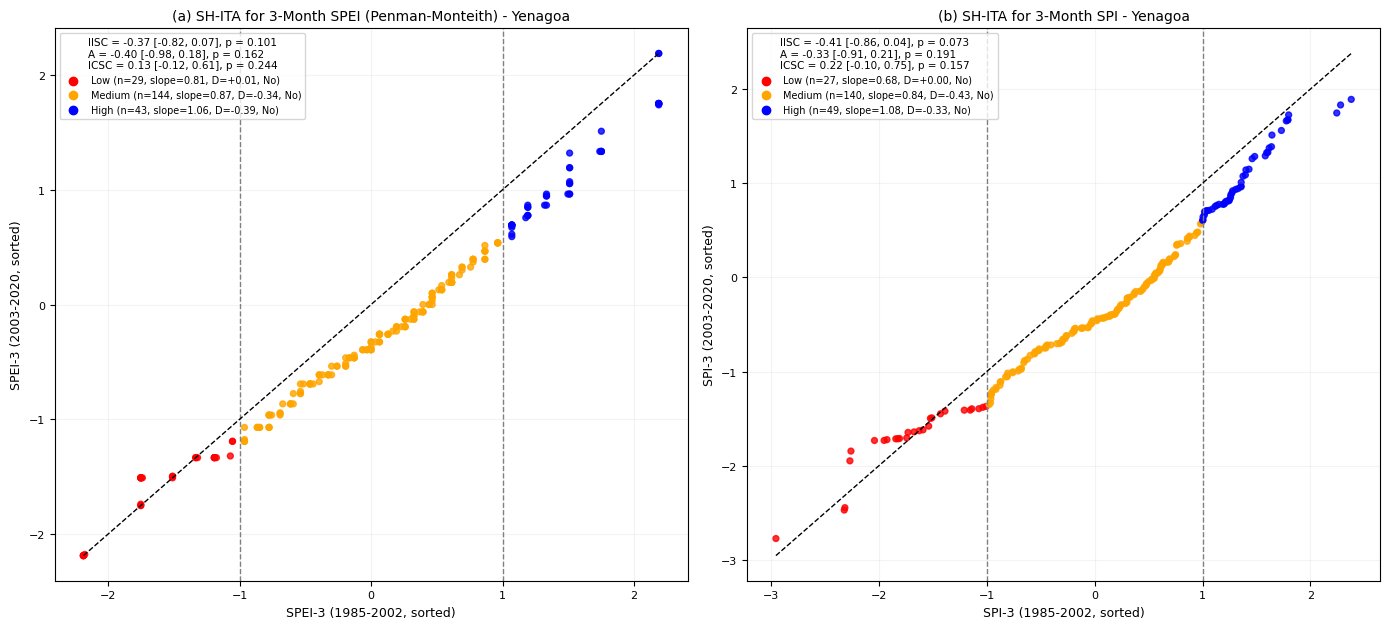

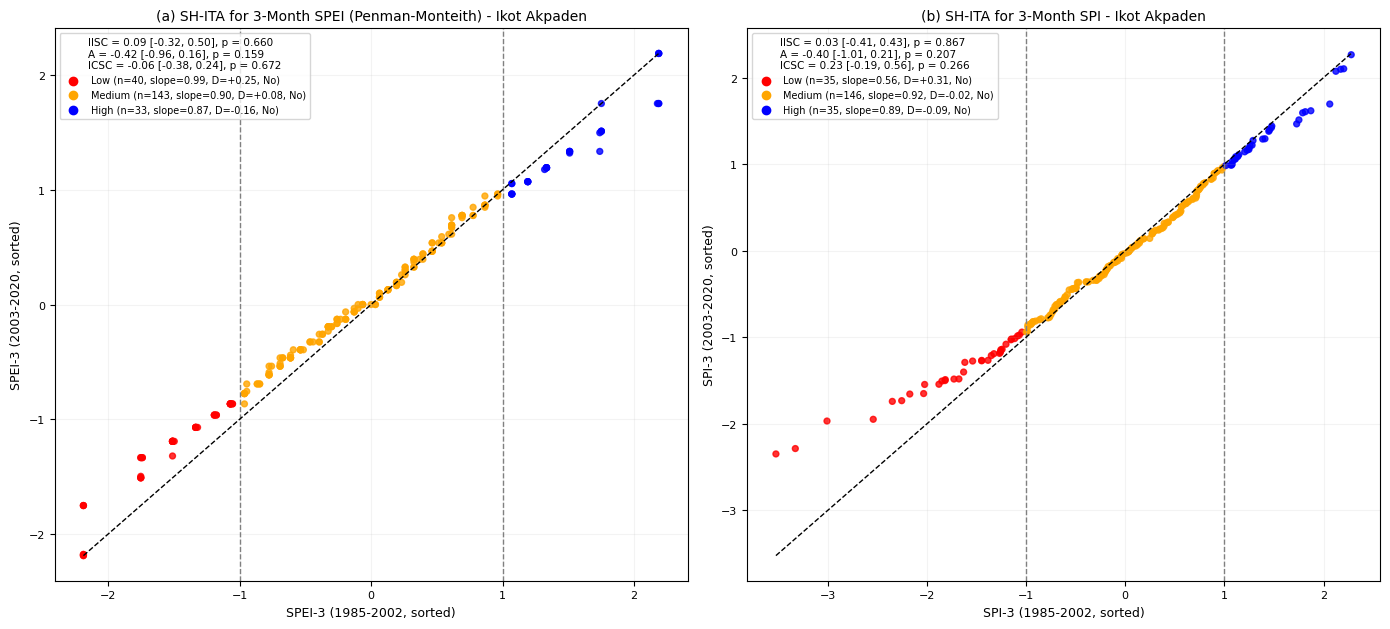

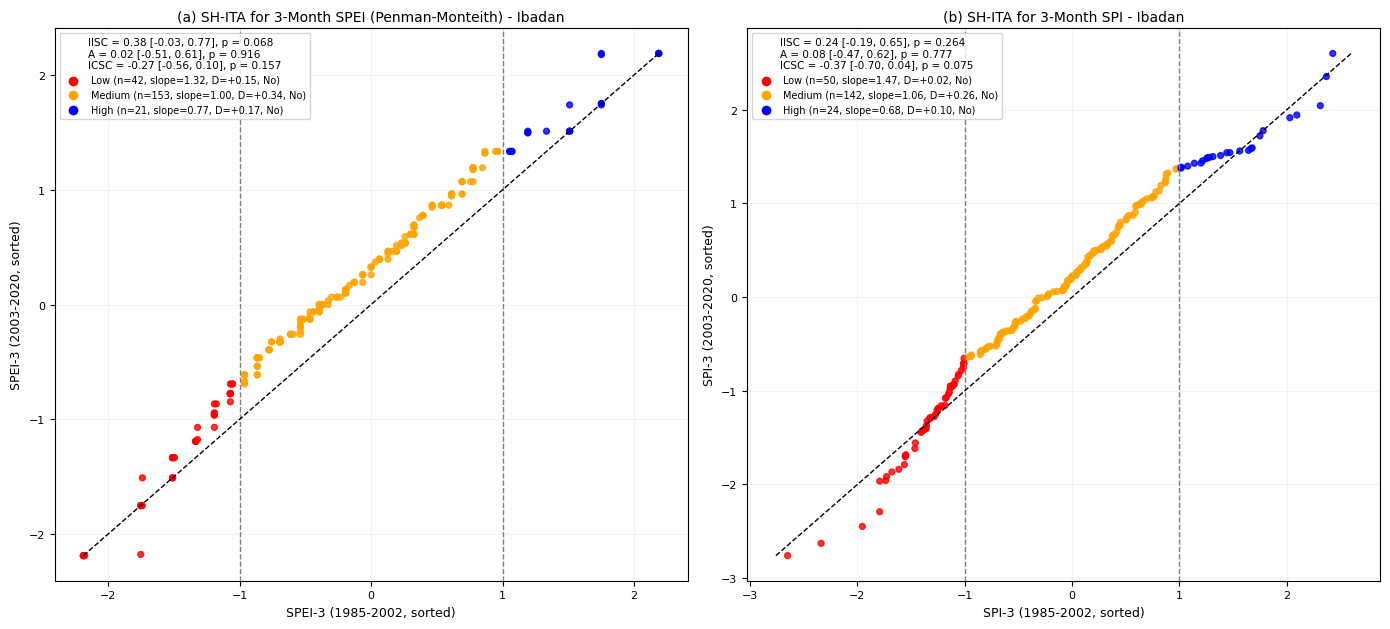

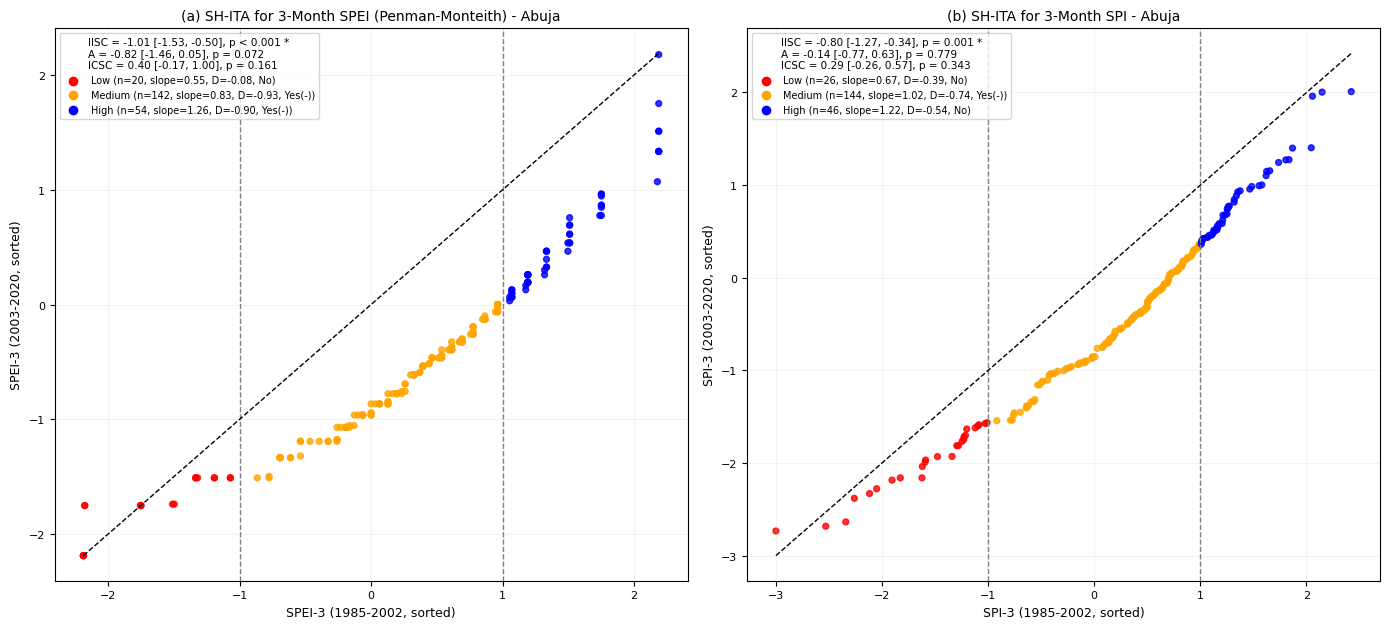

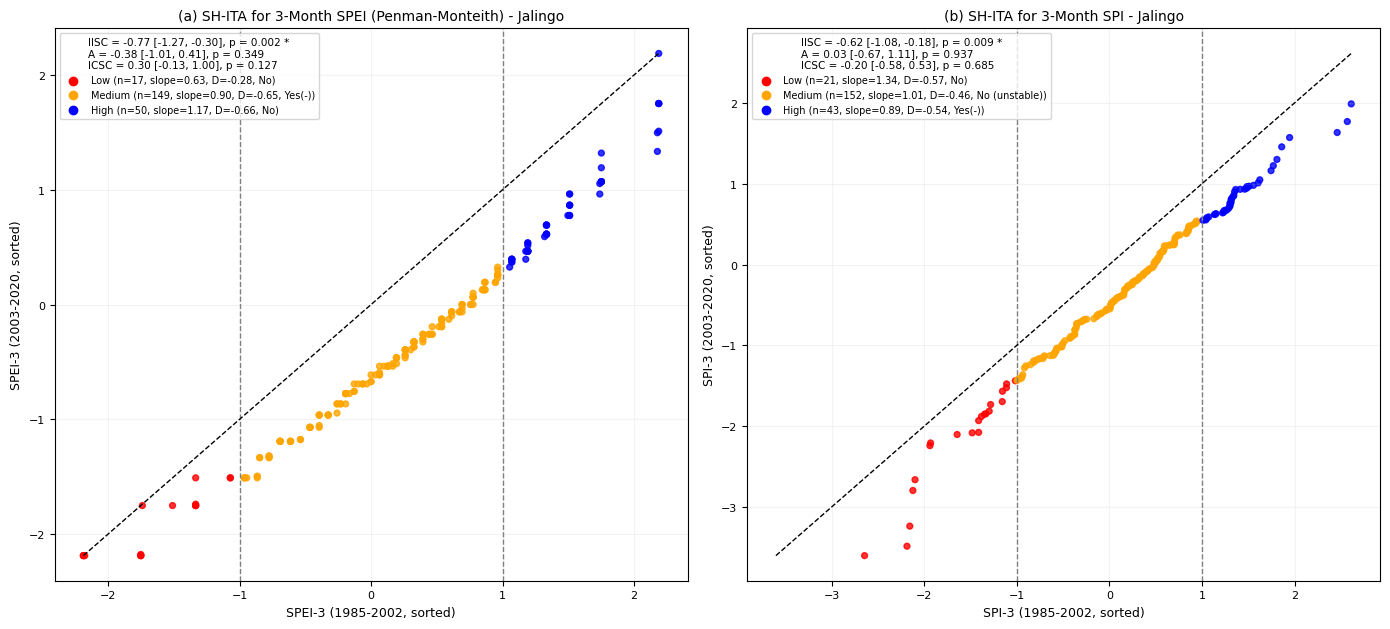

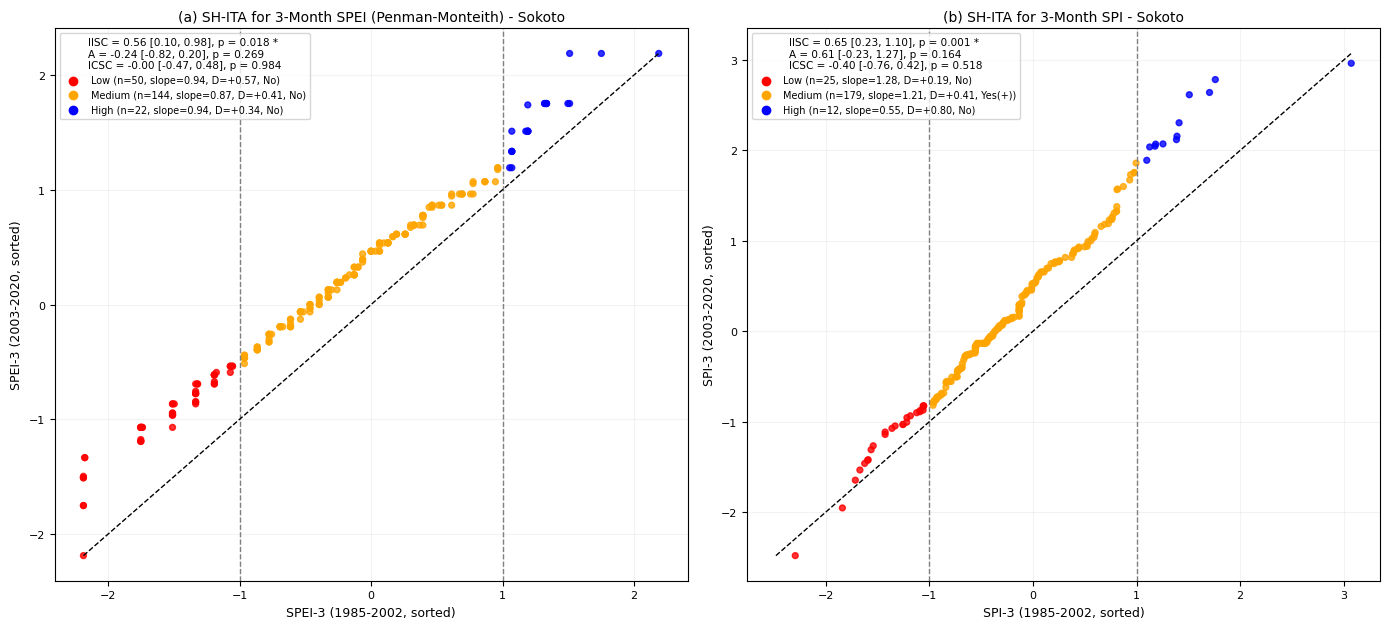

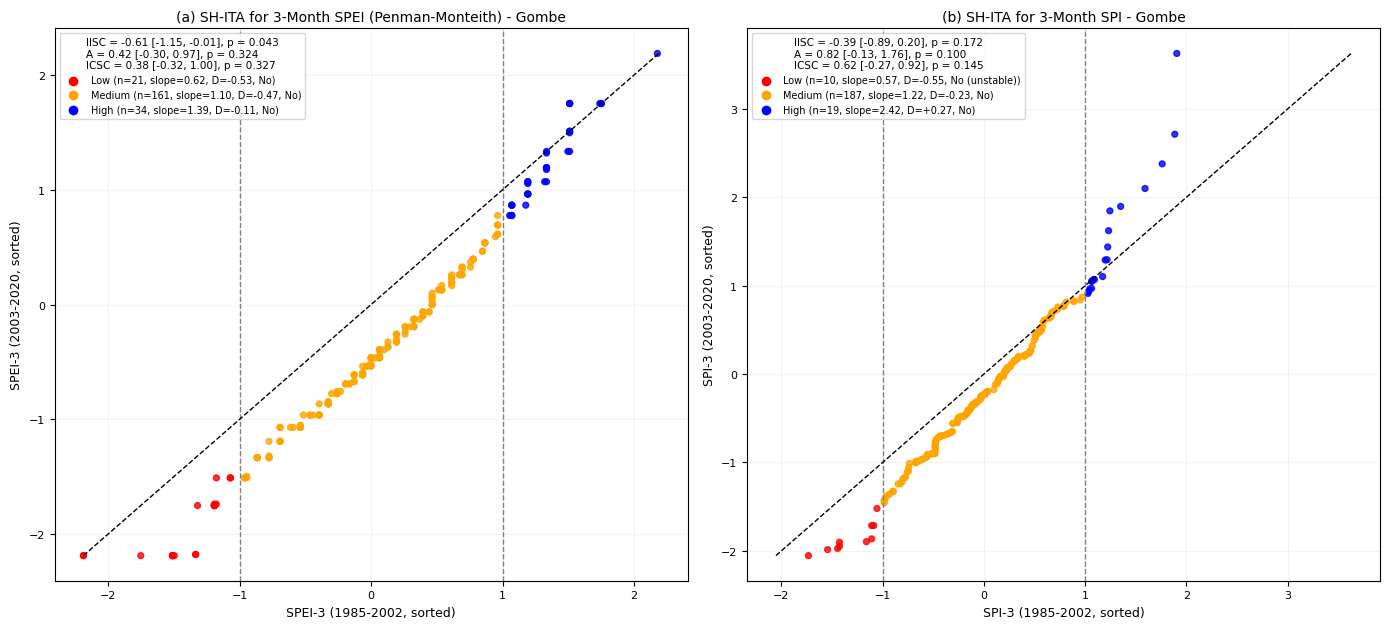

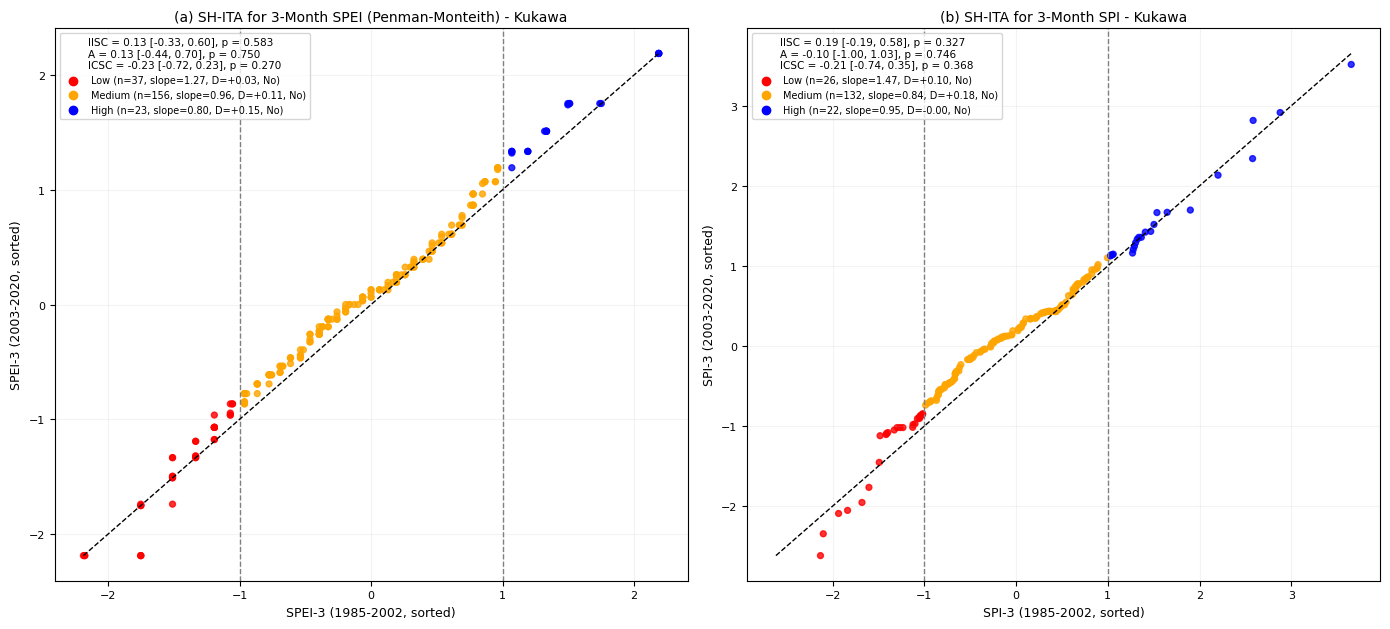

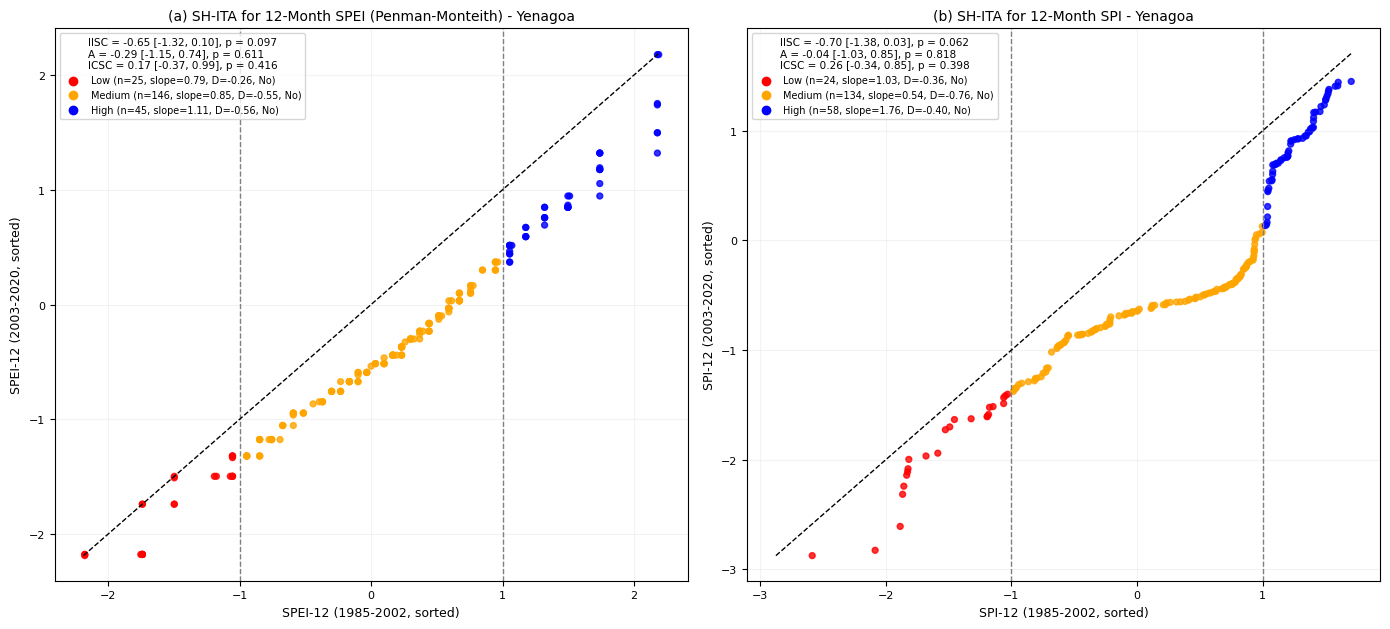

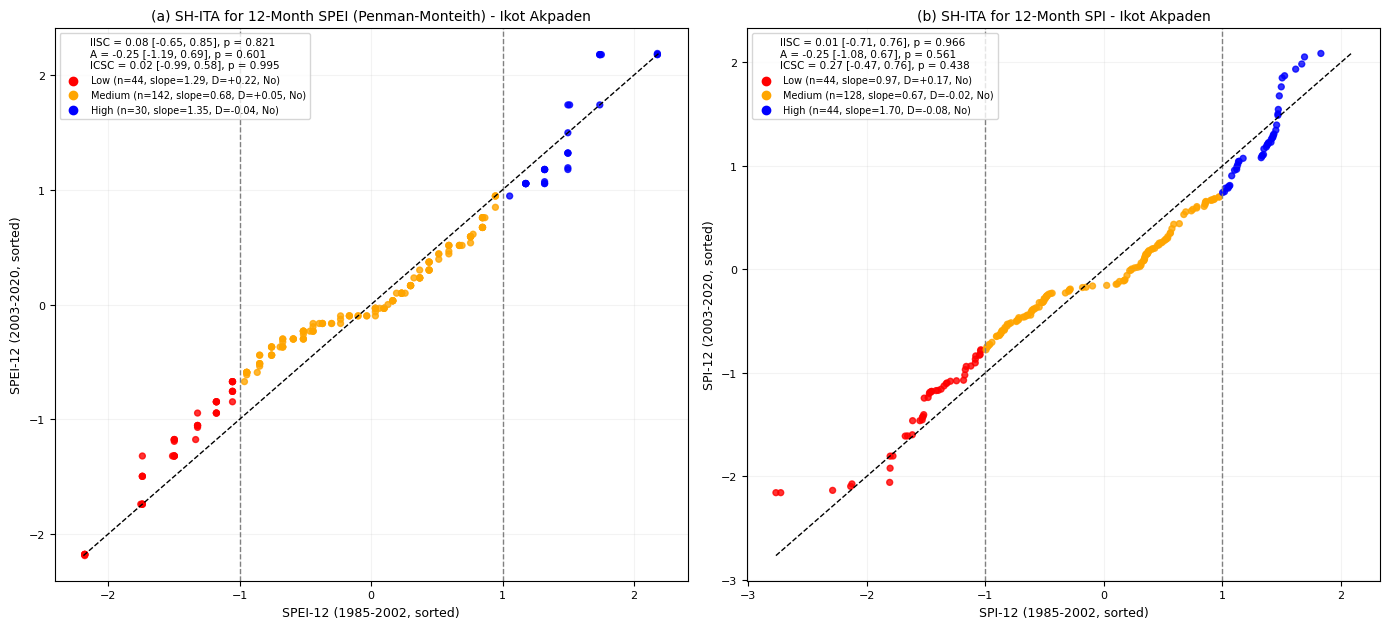

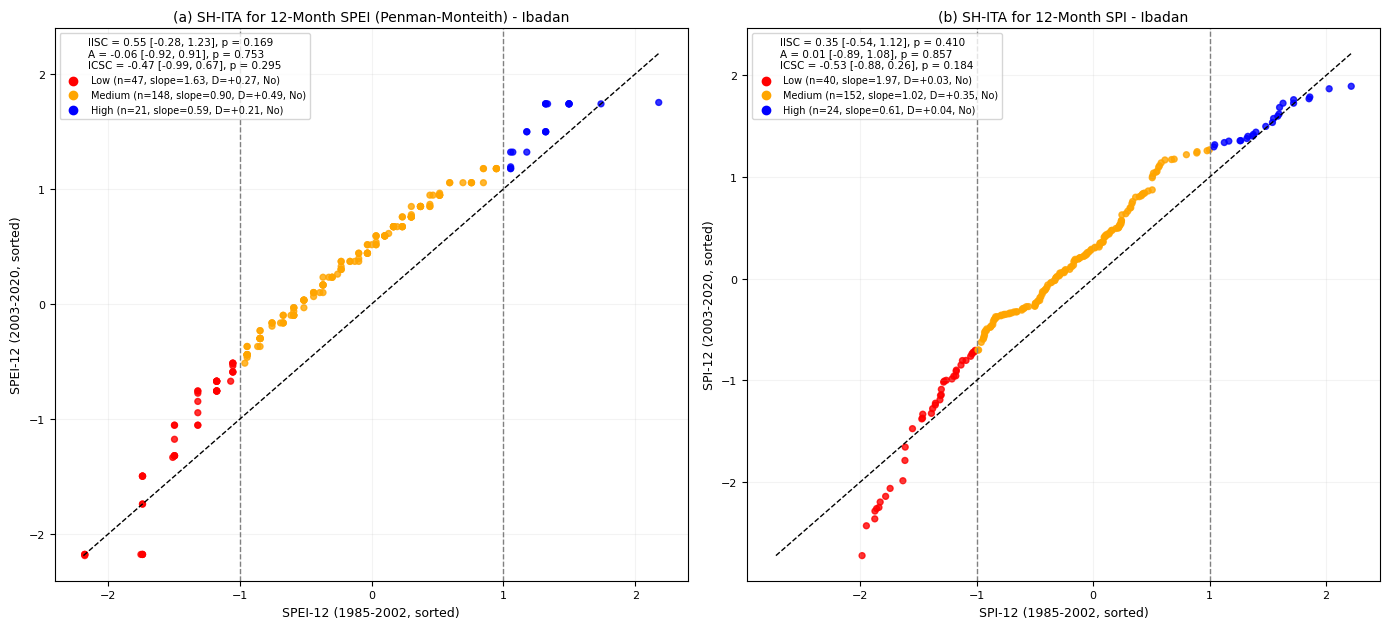

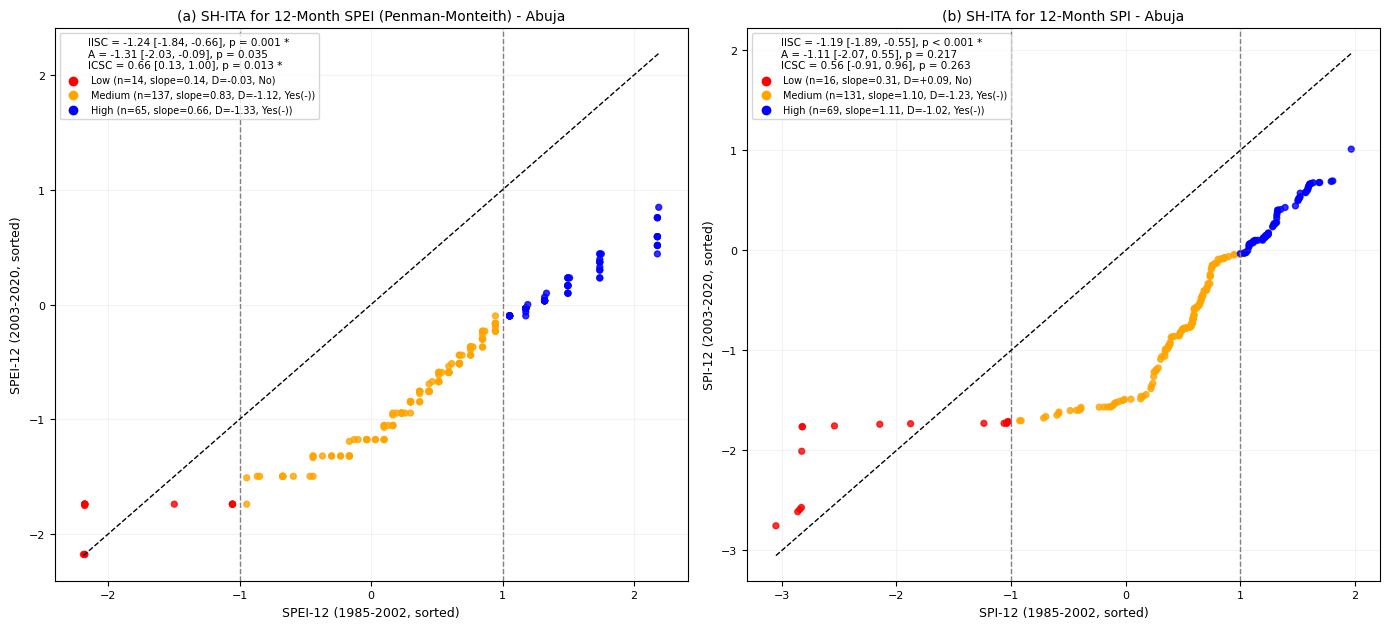

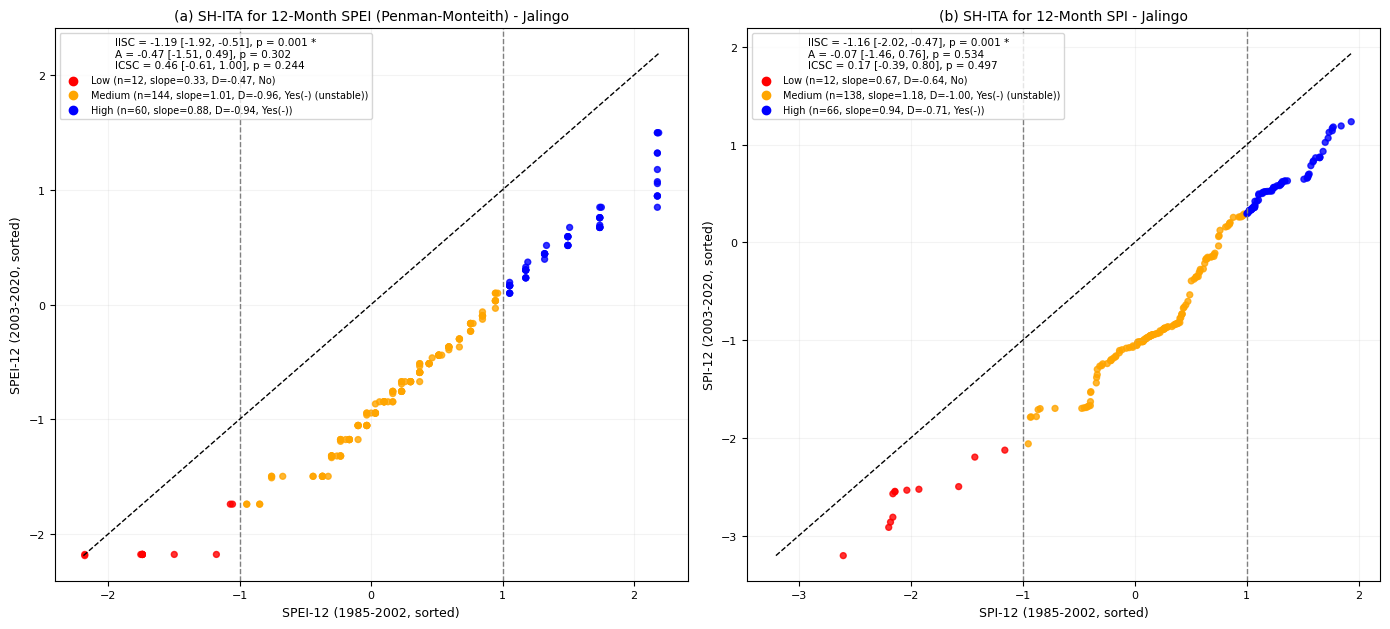

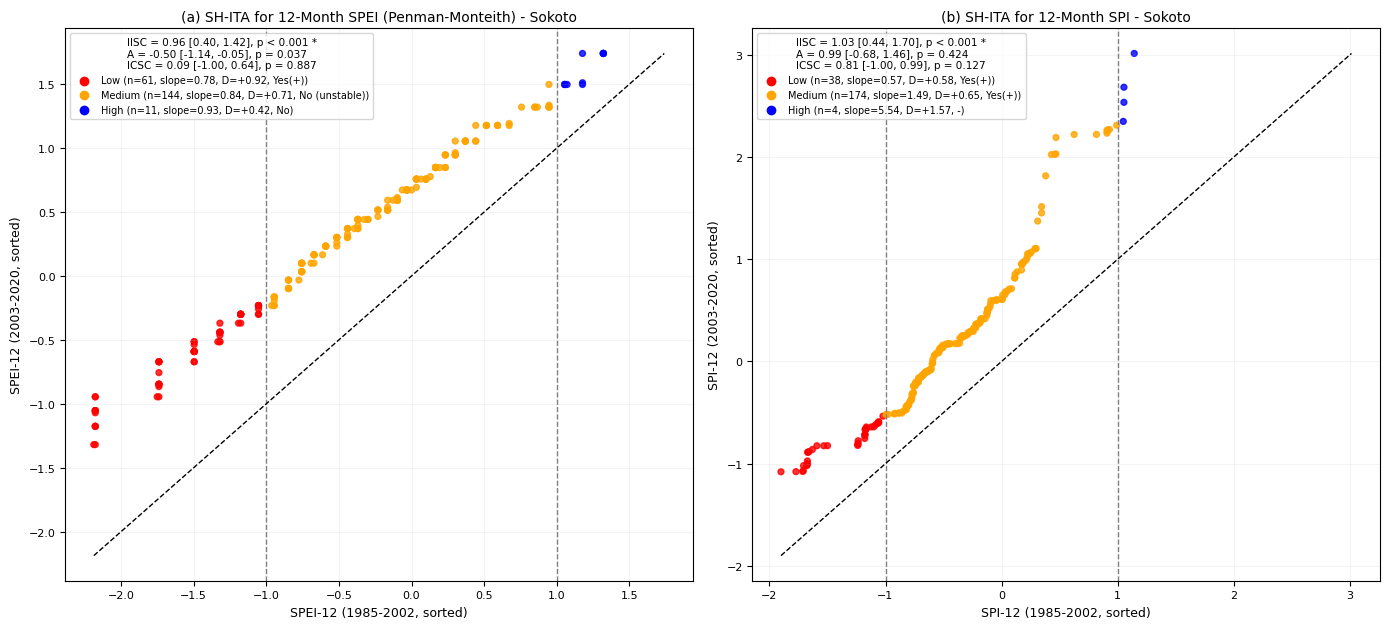

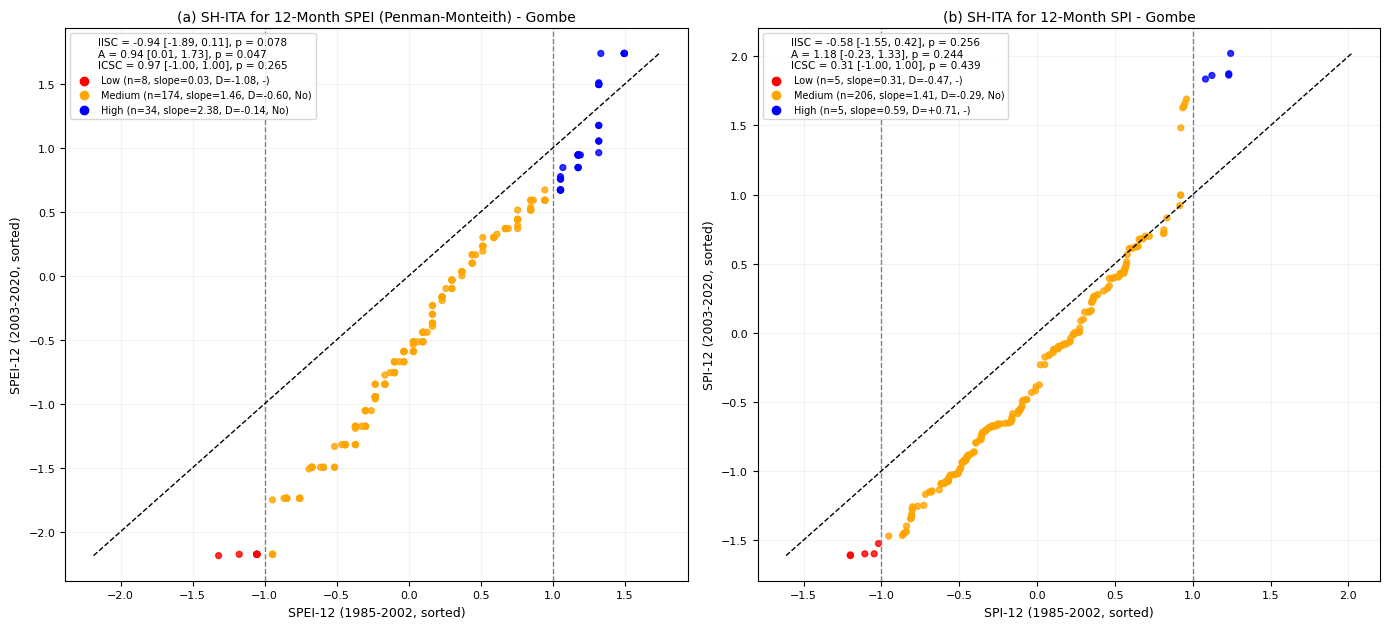

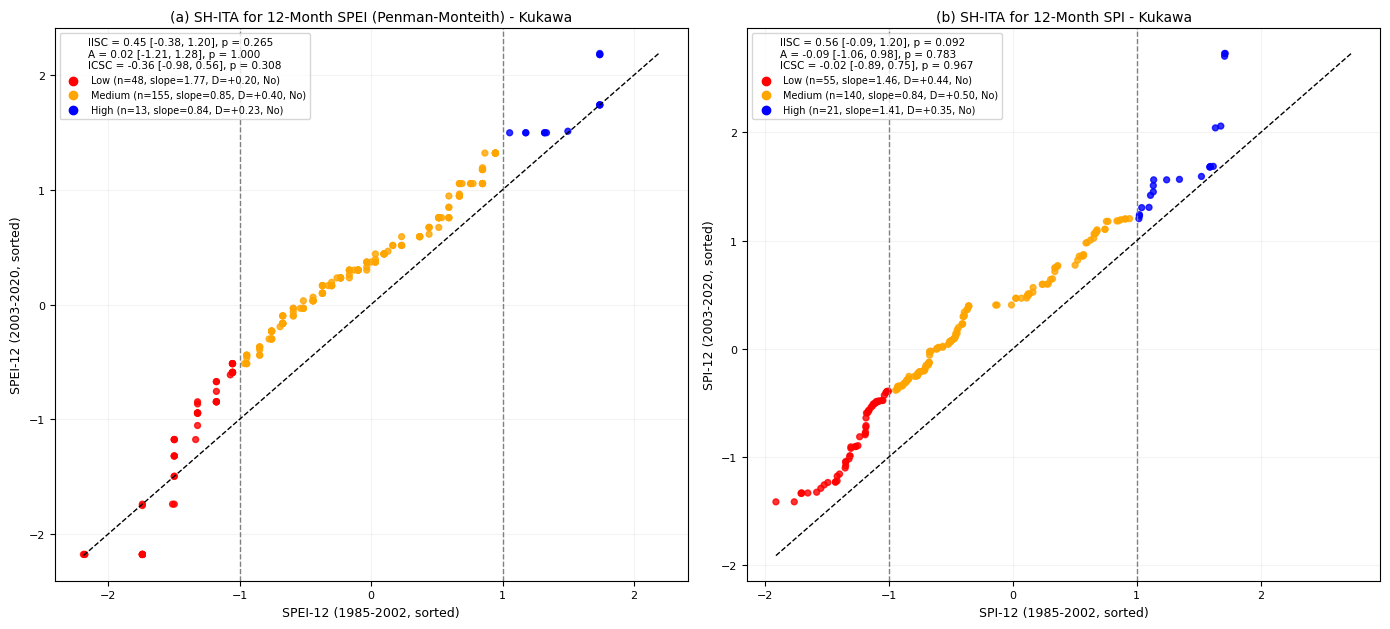

saved to sh_ita_outputs


In [15]:
COL = {'Low': 'red', 'Medium': 'orange', 'High': 'blue'}
R_ = PRIM.set_index(['location', 'index'])
def panel(ax, loc, kind, sc, tag, fs=7):
    s = SER[(loc, kind, sc)]
    x = s.loc[X_START:X_END].dropna().values; y = s.loc[Y_START:Y_END].dropna().values
    _, xs, ys, cls = ita_stats(x, y); r = R_.loc[(loc.title(), f'{kind}-{sc}')]
    names = np.array(['Low', 'Medium', 'High'])[cls]
    ax.axvline(-1, color='gray', ls='--', lw=1); ax.axvline(1, color='gray', ls='--', lw=1)
    ax.scatter(xs, ys, c=[COL[n] for n in names], alpha=0.8, s=18)
    lo, hi = min(xs.min(), ys.min()), max(xs.max(), ys.max()); ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
    for nm, cn in (('low', 'Low'), ('med', 'Medium'), ('high', 'High')):
        sl, d = r['slope_' + nm], r['D_' + nm]
        ax.scatter([], [], color=COL[cn], label='%s (n=%d, slope=%s, D=%s, %s)' % (cn, r['n_' + nm], '%.2f' % sl if np.isfinite(sl) else 'N/A',
                   '%+.2f' % d if np.isfinite(d) else 'N/A', r['final_' + nm]))
    pf = lambda p: ('< 0.001' if p < 0.001 else '= %.3f' % p) if np.isfinite(p) else 'n/a'
    star = lambda k: ' *' if r[k + '_clear'] else ''
    ax.legend(title='IISC = %s, p %s%s\nA = %s, p %s%s\nICSC = %s, p %s%s' % (ci(r, 'IISC'), pf(r['p_IISC']), star('IISC'), ci(r, 'A'), pf(r['p_A']), star('A'), ci(r, 'ICSC'), pf(r['p_ICSC']), star('ICSC')), loc='upper left', fontsize=fs, title_fontsize=fs + 0.5)
    nm_idx = 'SPEI (Penman-Monteith)' if kind == 'SPEI' else 'SPI'
    ax.set_title('%s SH-ITA for %d-Month %s - %s' % (tag, sc, nm_idx, loc.title()), fontsize=fs + 3)
    ax.set_xlabel('%s-%d (1985-2002, sorted)' % (kind, sc), fontsize=fs + 2); ax.set_ylabel('%s-%d (2003-2020, sorted)' % (kind, sc), fontsize=fs + 2); ax.tick_params(labelsize=fs + 1); ax.grid(alpha=0.15)
figdir = os.path.join(OUT, 'figures'); os.makedirs(figdir, exist_ok=True)
pdf = PdfPages(os.path.join(OUT, 'SH-ITA_final_PM_figures.pdf')); k = 0
for sc in (3, 12):
    for loc in order:
        k += 1; fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
        panel(axes[0], loc, 'SPEI', sc, '(a)'); panel(axes[1], loc, 'SPI', sc, '(b)')
        fig.tight_layout(); base = os.path.join(figdir, 'Fig_%02d_%dmonth_%s' % (k, sc, loc.replace(' ', '_')))
        fig.savefig(base + '.png', dpi=300); fig.savefig(base + '.pdf')   # PNG for Word, vector PDF for the journal
        pdf.savefig(fig); display(fig); plt.close(fig)
pdf.close()
with zipfile.ZipFile(os.path.join(OUT, 'SH-ITA_final_PM_figures.zip'), 'w') as z:
    for f in sorted(os.listdir(figdir)): z.write(os.path.join(figdir, f), f)
print('saved to', OUT)

## Main-text Figure 4: two representative SH-ITA plots (PDF and PNG)

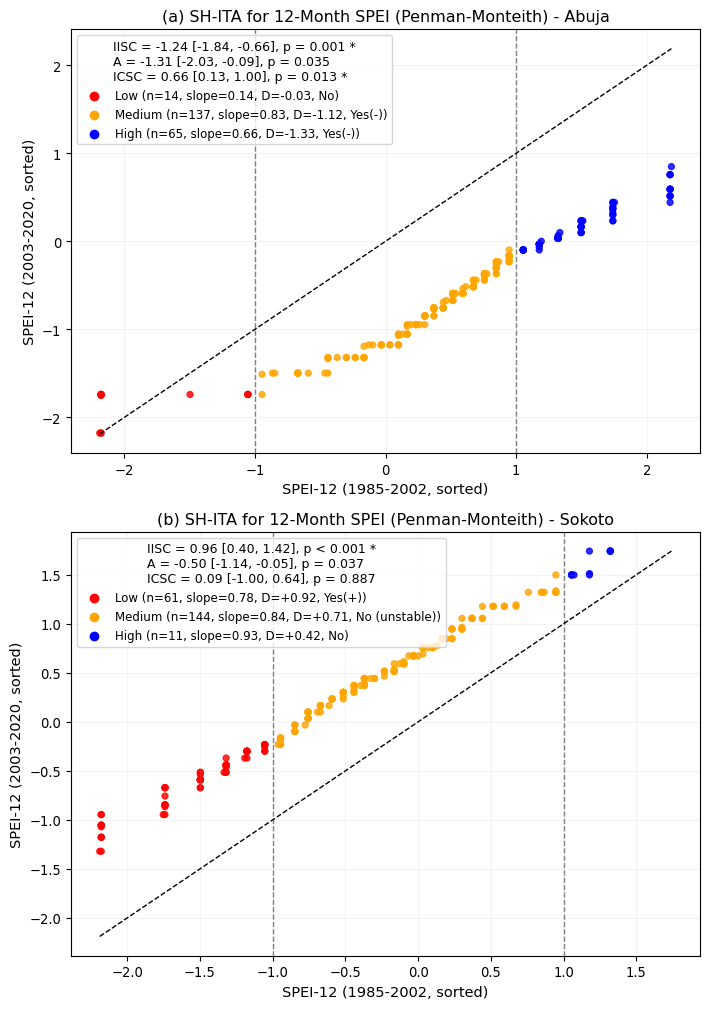

saved Fig4_representative_SH-ITA (.png and .pdf)


In [16]:
fig, axes = plt.subplots(2, 1, figsize=(7.2, 10.2))
panel(axes[0], 'ABUJA', 'SPEI', 12, '(a)', fs=8.5); panel(axes[1], 'SOKOTO', 'SPEI', 12, '(b)', fs=8.5)
fig.tight_layout(); fig.savefig(os.path.join(OUT, 'Fig4_representative_SH-ITA.png'), dpi=300); fig.savefig(os.path.join(OUT, 'Fig4_representative_SH-ITA.pdf')); display(fig); plt.close(fig)
print('saved Fig4_representative_SH-ITA (.png and .pdf)')